In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

#this sets the size of the plot to something useful
plt.rcParams["figure.figsize"] = (20,15)

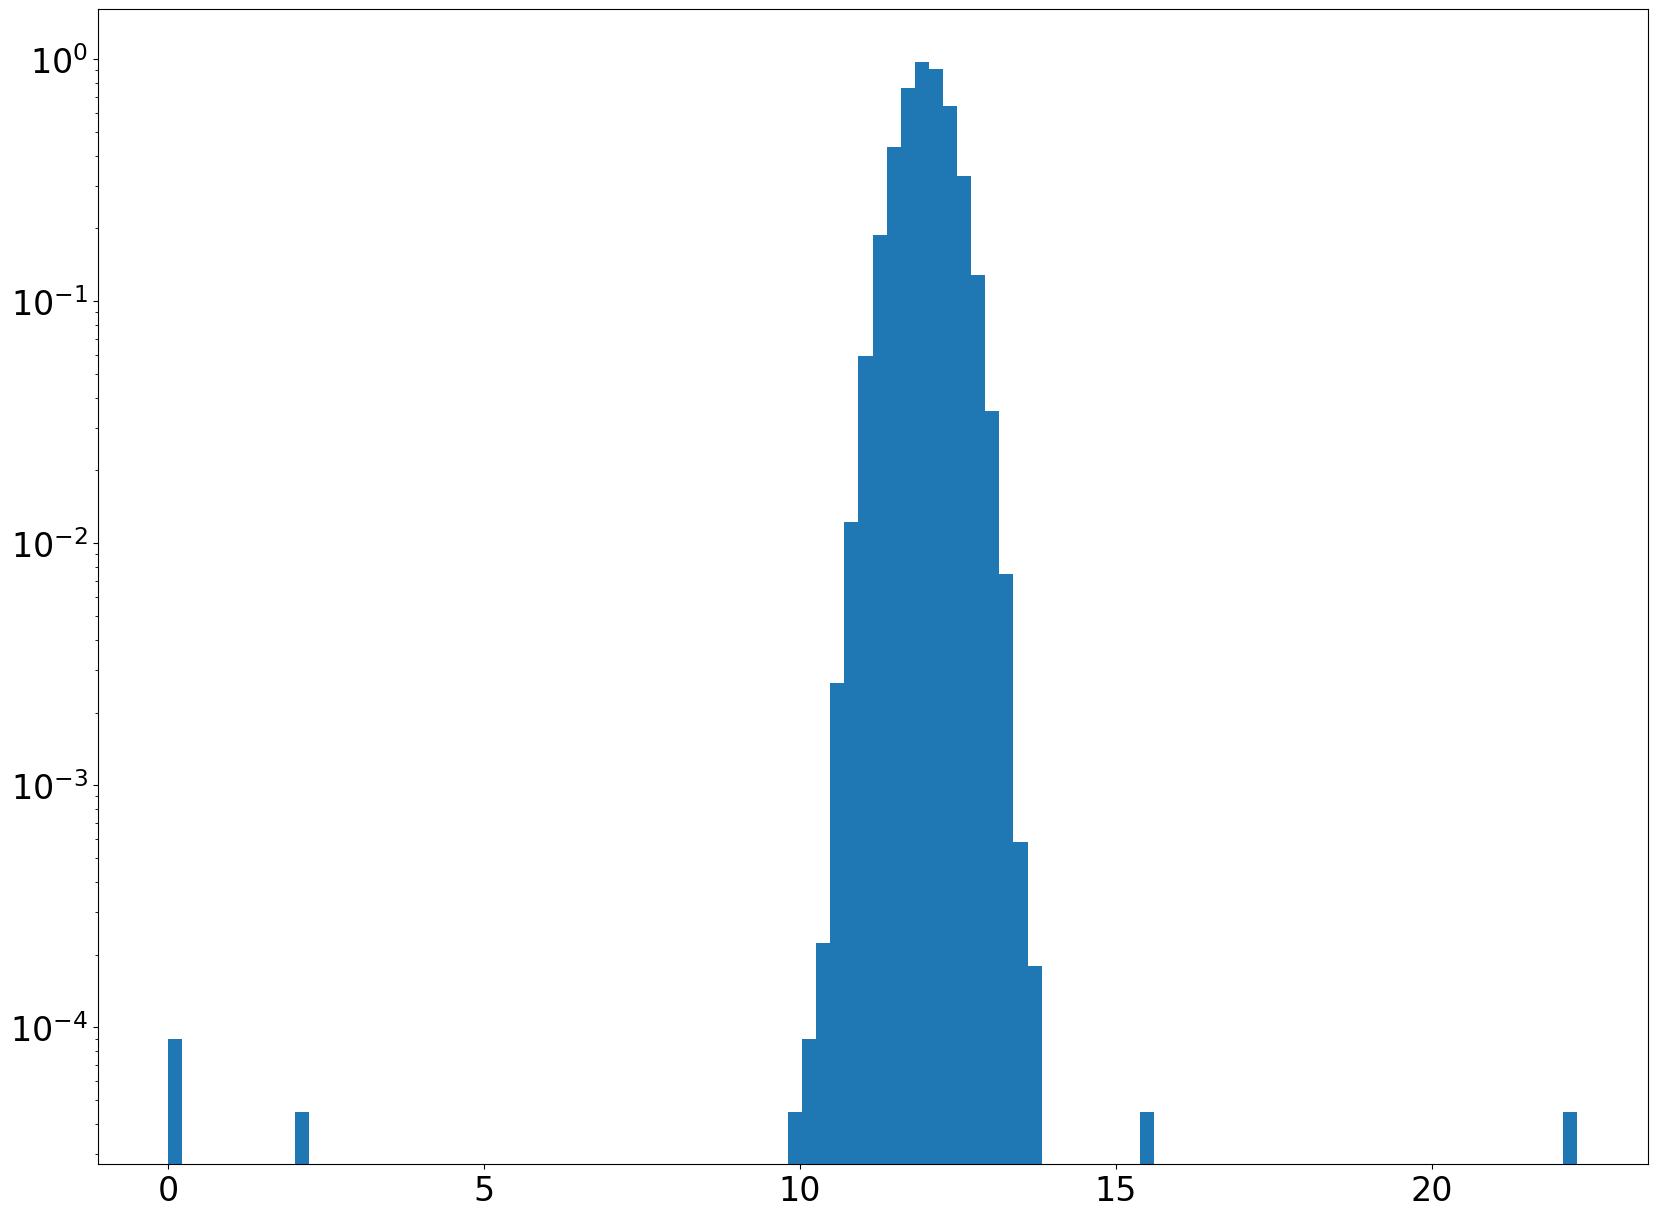

In [2]:
d = np.append(stats.norm.rvs(loc = 12., scale = 0.4, size = 100000), [10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7])
fig, ax = plt.subplots(1, 1)
ax.hist(d,100, density=True)
plt.tick_params(labelsize = 24)
plt.yscale('log')
#x = np.linspace(4.95,5.05,1000)
#ax.plot(x,stats.norm.pdf(x,loc = 5., scale = 0.01),linewidth = 8,alpha = 0.7)
plt.show()

### Problem 1.A
#### 1. State the question
How many standard deviations from the expected temperature should the measurement be before we reject it?\
I chose this because this is a two-tailed statistical test, and it will help eliminate unusually high and unusually low temperatures.

#### 2. The math
Using a threshold of $3\sigma$ we want: $\lvert T-12 \rvert>3(0.4)$ that would give us an accecptable range of $10.8\geq T\geq13.2$ 

#### 3. Making the truth table

In [3]:
mean = 12
sigma = 0.4
threshold = 4.22

test_bad = np.abs(d - mean) > threshold * sigma

true_bad = np.zeros(len(d), dtype=bool)
true_bad[-8:] = True # Tells us the last 8 are actually bad

# Constructing the truth table
good_accepted = np.sum(~true_bad & ~test_bad)
good_rejected = np.sum(~true_bad & test_bad)

bad_accepted = np.sum(true_bad & ~test_bad)
bad_rejected = np.sum(true_bad & test_bad)

print("                    Actually Good    Actually Bad")
print(f"Test Accepted       {good_accepted:<17} {bad_accepted}")
print(f"Test Rejected       {good_rejected:<17} {bad_rejected}")

                    Actually Good    Actually Bad
Test Accepted       99996             1
Test Rejected       4                 7


### Problem 1.B & 1.C
Increasing the rejection threshold from $3\sigma$ to $4.22\sigma$ reduced the number of good measurements incorrectly rejected from ~270 to 4, while still identifying 7 of the 8 bad measurements. Increasing the threshold further to $5\sigma$ eliminated all the rejections of good measurements, but also allowed 3 of the 8 bad measurements to pass.

This demonstrates that a larger rejection threshold reduces the amount of rejected good measurements but can let more bad data through. For this dataset, $4.22sigma$ provides the best balance among the thresholds tested, since it preserves nearly all good measurements while still rejecting most of the bad ones.

We could lower our rejection threshold enough to reject the  12.7 K measurement that is accepted, but doing so would also reject a substantial number of genuinely good measurements. This means there's no way to reliably identify that measurement as bad based on its temperature alone.

### Problem 2

<>:9: SyntaxWarning: invalid escape sequence '\D'
<>:10: SyntaxWarning: invalid escape sequence '\D'
<>:9: SyntaxWarning: invalid escape sequence '\D'
<>:10: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_2668/2121784878.py:9: SyntaxWarning: invalid escape sequence '\D'
  plt.ylabel("$\Delta$y arcseconds", fontsize = 18)
/tmp/ipykernel_2668/2121784878.py:10: SyntaxWarning: invalid escape sequence '\D'
  plt.xlabel("$\Delta$x arcseconds", fontsize = 18)


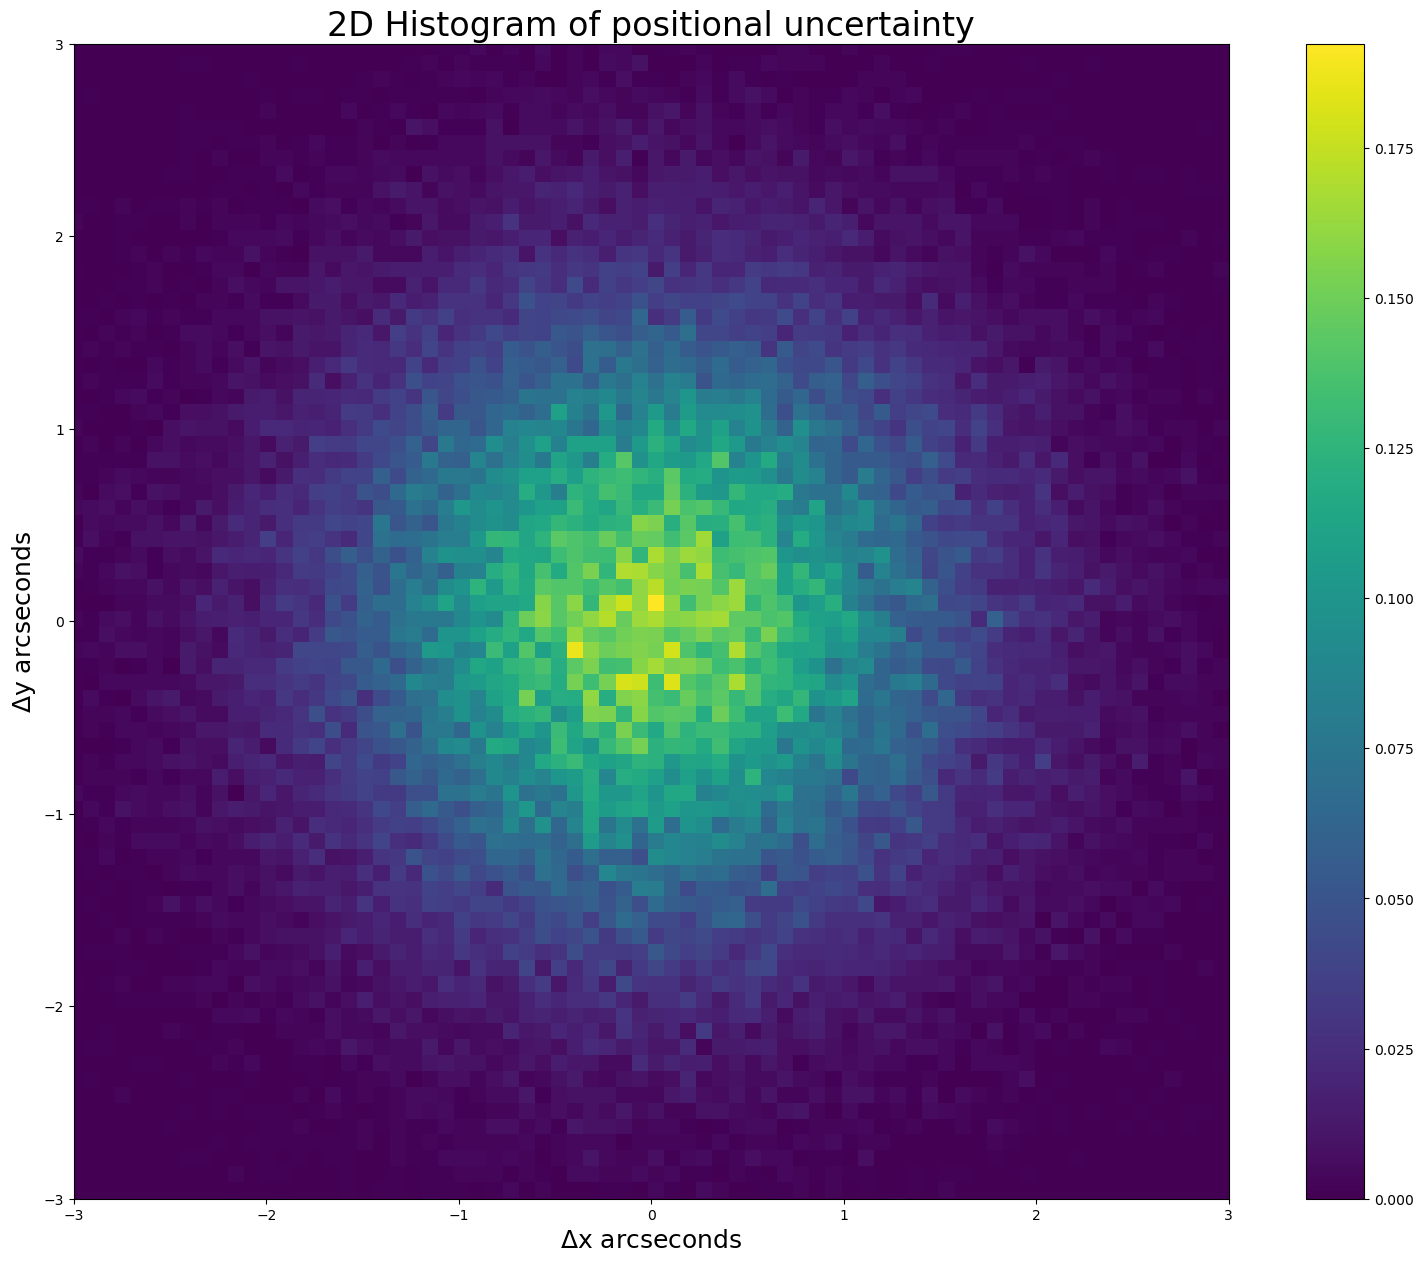

In [4]:
a = np.vstack((stats.norm.rvs( scale = 1, size = 100000), stats.norm.rvs( scale = 1, size = 100000)))
a.shape
fig, ax = plt.subplots(1, 1)
h = ax.hist2d(a[0,:],a[1,:],bins=100, density=True);
ax.set_aspect('equal', 'box')
plt.xlim([-3 , 3])
plt.ylim([-3 , 3])
plt.title("2D Histogram of positional uncertainty", fontsize = 24)
plt.ylabel("$\Delta$y arcseconds", fontsize = 18)
plt.xlabel("$\Delta$x arcseconds", fontsize = 18)
plt.colorbar(h[3], ax=ax)

#### Problem 2.1 State the question
How far must an object appear to move between observations before there's at least a $5\sigma$ probability of that displacement not being caused by random positional errors alone?

#### Problem 2.2 The math

$$r=\sqrt{\Delta x^2 + \Delta y^2}$$
Where $\Delta x$ and $\Delta y$ are gaussian distributions.

In [5]:
sigma = 1

p = stats.norm.sf(5)

# Displacement using the Rayleigh distribution
r = stats.rayleigh.isf(p, scale=sigma)

print(f"5-sigma probability: {p:.6e}")
print(f"Required displacement: {r:.3f} arcseconds")

5-sigma probability: 2.866516e-07
Required displacement: 5.489 arcseconds


### Problem 3
#### problem 3.1 The question

Given a poisson distributuion of cosmic rays across 15 days (7200 minutes) what is the probability of seeing 6800 rays due to the Moon's shadow?

#### 3.2 The math

What is the probability when you integrate the poissonian distribution centered around 7200 from 0 to 6800 and what is the associated normal sigma value?

#### 3.3 Sigma Value

In [6]:
k = 6800
mu = 7200

q = stats.poisson.cdf(k, mu, loc = 0)

sigma = stats.norm.isf(q)

print(f"Probability: {q:.3e}")
print(f"Sigma: {sigma:.3f}")

Probability: 1.013e-06
Sigma: 4.751
